In [3]:
import pandas as pd
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Prepare Data

In [4]:
df = pd.read_csv('ecommerce.csv')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,554697,21166,COOK WITH WINE METAL SIGN,1,5/25/2011 17:31,2.08,14584,United Kingdom
1,561038,82482,WOODEN PICTURE FRAME WHITE FINISH,2,7/24/2011 11:58,2.55,17114,United Kingdom
2,560552,23192,BUNDLE OF 3 ALPHABET EXERCISE BOOKS,1,7/19/2011 12:54,1.65,15311,United Kingdom
3,559884,85183B,CHARLIE & LOLA WASTEPAPER BIN FLORA,12,7/13/2011 11:34,1.25,16843,United Kingdom
4,544450,21789,KIDS RAIN MAC PINK,3,2/20/2011 12:23,0.85,17811,United Kingdom


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4870 entries, 0 to 4869
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   InvoiceNo    4870 non-null   int64  
 1   StockCode    4870 non-null   object 
 2   Description  4870 non-null   object 
 3   Quantity     4870 non-null   int64  
 4   InvoiceDate  4870 non-null   object 
 5   UnitPrice    4870 non-null   float64
 6   CustomerID   4870 non-null   int64  
 7   Country      4870 non-null   object 
dtypes: float64(1), int64(3), object(4)
memory usage: 304.5+ KB


In [12]:
df.shape

(4870, 8)

# Data Preprocessing

In [7]:
# Convert InvoiceDate from object to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4870 entries, 0 to 4869
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    4870 non-null   int64         
 1   StockCode    4870 non-null   object        
 2   Description  4870 non-null   object        
 3   Quantity     4870 non-null   int64         
 4   InvoiceDate  4870 non-null   datetime64[ns]
 5   UnitPrice    4870 non-null   float64       
 6   CustomerID   4870 non-null   int64         
 7   Country      4870 non-null   object        
dtypes: datetime64[ns](1), float64(1), int64(3), object(3)
memory usage: 304.5+ KB


In [8]:
# Filter out any canceled or invalid orders (Quantity <= 0)
df_clean = df[df['Quantity'] > 0].copy()
df_clean

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,554697,21166,COOK WITH WINE METAL SIGN,1,2011-05-25 17:31:00,2.08,14584,United Kingdom
1,561038,82482,WOODEN PICTURE FRAME WHITE FINISH,2,2011-07-24 11:58:00,2.55,17114,United Kingdom
2,560552,23192,BUNDLE OF 3 ALPHABET EXERCISE BOOKS,1,2011-07-19 12:54:00,1.65,15311,United Kingdom
3,559884,85183B,CHARLIE & LOLA WASTEPAPER BIN FLORA,12,2011-07-13 11:34:00,1.25,16843,United Kingdom
4,544450,21789,KIDS RAIN MAC PINK,3,2011-02-20 12:23:00,0.85,17811,United Kingdom
...,...,...,...,...,...,...,...,...
4865,571883,23263,SET OF 3 WOODEN HEART DECORATIONS,1,2011-10-19 13:58:00,1.25,14704,United Kingdom
4866,545530,21922,UNION STRIPE WITH FRINGE HAMMOCK,12,2011-03-03 13:45:00,6.95,17416,United Kingdom
4867,540458,21125,SET 6 FOOTBALL CELEBRATION CANDLES,12,2011-01-07 12:28:00,1.25,12501,Germany
4868,574289,22999,TRAVEL CARD WALLET VINTAGE LEAF,24,2011-11-03 15:16:00,0.42,17750,United Kingdom


In [9]:
# Create the Monetary metric (TotalSales)
df_clean['TotalSales'] = df_clean['Quantity'] * df_clean['UnitPrice']
df_clean

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,554697,21166,COOK WITH WINE METAL SIGN,1,2011-05-25 17:31:00,2.08,14584,United Kingdom,2.08
1,561038,82482,WOODEN PICTURE FRAME WHITE FINISH,2,2011-07-24 11:58:00,2.55,17114,United Kingdom,5.10
2,560552,23192,BUNDLE OF 3 ALPHABET EXERCISE BOOKS,1,2011-07-19 12:54:00,1.65,15311,United Kingdom,1.65
3,559884,85183B,CHARLIE & LOLA WASTEPAPER BIN FLORA,12,2011-07-13 11:34:00,1.25,16843,United Kingdom,15.00
4,544450,21789,KIDS RAIN MAC PINK,3,2011-02-20 12:23:00,0.85,17811,United Kingdom,2.55
...,...,...,...,...,...,...,...,...,...
4865,571883,23263,SET OF 3 WOODEN HEART DECORATIONS,1,2011-10-19 13:58:00,1.25,14704,United Kingdom,1.25
4866,545530,21922,UNION STRIPE WITH FRINGE HAMMOCK,12,2011-03-03 13:45:00,6.95,17416,United Kingdom,83.40
4867,540458,21125,SET 6 FOOTBALL CELEBRATION CANDLES,12,2011-01-07 12:28:00,1.25,12501,Germany,15.00
4868,574289,22999,TRAVEL CARD WALLET VINTAGE LEAF,24,2011-11-03 15:16:00,0.42,17750,United Kingdom,10.08


In [13]:
df_clean.shape

(4870, 9)

In [14]:
df_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,554697,21166,COOK WITH WINE METAL SIGN,1,2011-05-25 17:31:00,2.08,14584,United Kingdom,2.08
1,561038,82482,WOODEN PICTURE FRAME WHITE FINISH,2,2011-07-24 11:58:00,2.55,17114,United Kingdom,5.10
2,560552,23192,BUNDLE OF 3 ALPHABET EXERCISE BOOKS,1,2011-07-19 12:54:00,1.65,15311,United Kingdom,1.65
3,559884,85183B,CHARLIE & LOLA WASTEPAPER BIN FLORA,12,2011-07-13 11:34:00,1.25,16843,United Kingdom,15.00
4,544450,21789,KIDS RAIN MAC PINK,3,2011-02-20 12:23:00,0.85,17811,United Kingdom,2.55


# Exploratory Data Analysis (EDA) Visualizations

In [15]:
sns.set_theme(style="whitegrid")

## Top 5 Countries by Revenue

/tmp/ipykernel_2272/3716125861.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, palette='PuBu')


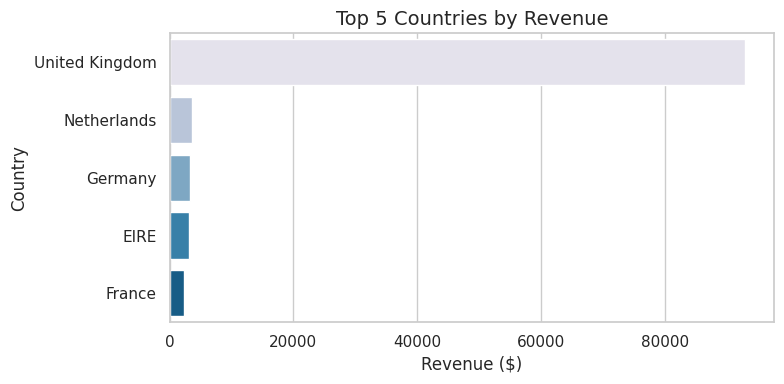

In [17]:
plt.figure(figsize=(8, 4))
top_countries = df_clean.groupby('Country')['TotalSales'].sum().sort_values(ascending=False).head(5)
sns.barplot(x=top_countries.values, y=top_countries.index, palette='PuBu')
plt.title('Top 5 Countries by Revenue', fontsize=14)
plt.xlabel('Revenue ($)')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

## Monthly Sales Revenue

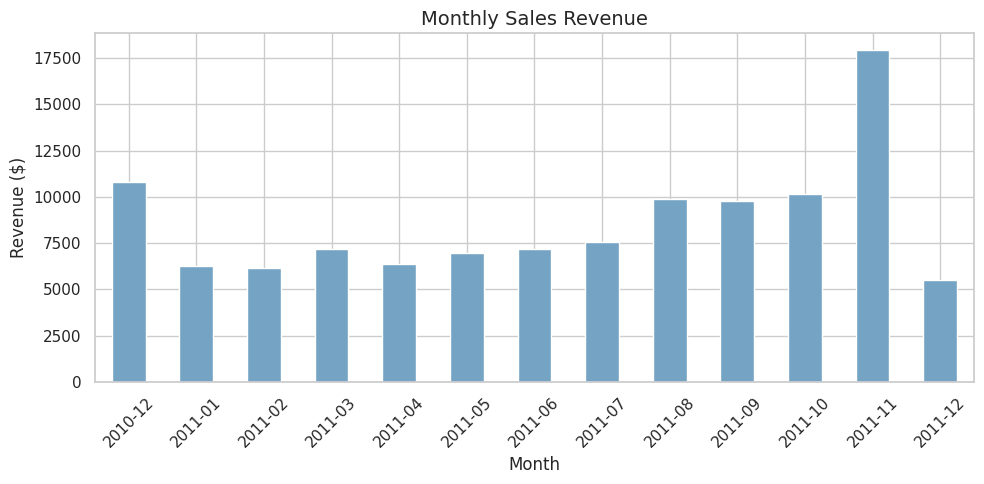

In [24]:
plt.figure(figsize=(10, 5))

# Group by Year-Month
monthly_sales = df_clean.groupby(df_clean['InvoiceDate'].dt.to_period('M'))['TotalSales'].sum()
monthly_sales.plot(kind='bar', color='#75a3c4')

plt.title('Monthly Sales Revenue', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Revenue ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# RFM

In [28]:
# Create a snapshot date (1 day after the last transaction in the dataset)
snapshot_date = df_clean['InvoiceDate'].max() + dt.timedelta(days=1)
df_clean

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSales
0,554697,21166,COOK WITH WINE METAL SIGN,1,2011-05-25 17:31:00,2.08,14584,United Kingdom,2.08
1,561038,82482,WOODEN PICTURE FRAME WHITE FINISH,2,2011-07-24 11:58:00,2.55,17114,United Kingdom,5.10
2,560552,23192,BUNDLE OF 3 ALPHABET EXERCISE BOOKS,1,2011-07-19 12:54:00,1.65,15311,United Kingdom,1.65
3,559884,85183B,CHARLIE & LOLA WASTEPAPER BIN FLORA,12,2011-07-13 11:34:00,1.25,16843,United Kingdom,15.00
4,544450,21789,KIDS RAIN MAC PINK,3,2011-02-20 12:23:00,0.85,17811,United Kingdom,2.55
...,...,...,...,...,...,...,...,...,...
4865,571883,23263,SET OF 3 WOODEN HEART DECORATIONS,1,2011-10-19 13:58:00,1.25,14704,United Kingdom,1.25
4866,545530,21922,UNION STRIPE WITH FRINGE HAMMOCK,12,2011-03-03 13:45:00,6.95,17416,United Kingdom,83.40
4867,540458,21125,SET 6 FOOTBALL CELEBRATION CANDLES,12,2011-01-07 12:28:00,1.25,12501,Germany,15.00
4868,574289,22999,TRAVEL CARD WALLET VINTAGE LEAF,24,2011-11-03 15:16:00,0.42,17750,United Kingdom,10.08


In [31]:
# Aggregate data by CustomerID
rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalSales': 'sum'
}).reset_index()
rfm.head()

,CustomerID,InvoiceDate,InvoiceNo,TotalSales
0,12347,367,1,25.50
1,12349,19,1,17.85
2,12354,232,1,19.90
3,12356,326,1,50.40
4,12357,33,1,100.08


In [33]:
# Rename columns for clarity
rfm.rename(columns={'InvoiceDate': 'Recency',
                    'InvoiceNo': 'Frequency',
                    'TotalSales': 'Monetary'}, inplace=True)
rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12347,367,1,25.50
1,12349,19,1,17.85
2,12354,232,1,19.90
3,12356,326,1,50.40
4,12357,33,1,100.08


# The Elbow Method

In [34]:
# Standardize the RFM variables
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm[['Recency', 'Frequency', 'Monetary']])
rfm_scaled

array([[ 2.29499815, -0.33477847, -0.15864213],
       [-0.95285566, -0.33477847, -0.19614896],
       [ 1.03505486, -0.33477847, -0.18609811],
       ...,
       [-0.43954543, -0.33477847, -0.21012209],
       [ 1.46436887, -0.33477847, -0.19614896],
       [-0.85952653,  1.39276426, -0.21502495]])

In [35]:
# Calculate Sum of Squared Errors (SSE) for different k values
sse = {}
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    sse[k] = kmeans.inertia_

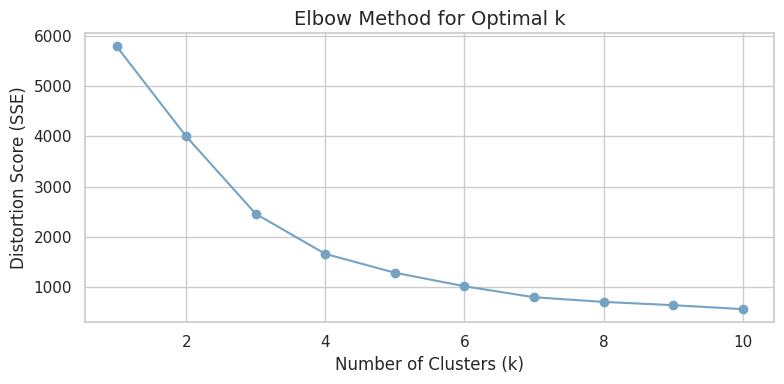

In [37]:
# Plot the Elbow Curve
plt.figure(figsize=(8, 4))
plt.plot(list(sse.keys()), list(sse.values()), marker='o', color='#75a3c4')
plt.title('Elbow Method for Optimal k', fontsize=14)
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Distortion Score (SSE)')
plt.tight_layout()
plt.show()

# K-Means Clustering & Visualizing Segments

In [40]:
# Apply K-Means with 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)
rfm.head()

,CustomerID,Recency,Frequency,Monetary,Cluster
0,12347,367,1,25.50,1
1,12349,19,1,17.85,0
2,12354,232,1,19.90,1
3,12356,326,1,50.40,1
4,12357,33,1,100.08,0


In [41]:
# Print the average RFM values for each cluster to understand their profiles
cluster_summary = rfm.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(2)
cluster_summary

Recency Frequency Monetary      
           mean      mean     mean count
Cluster                                 
0         53.21      2.16    52.03  1258
1        252.61      1.20    29.58   660
2          2.00     47.00   957.05     5
3         31.67      6.22  2446.87     9

/tmp/ipykernel_2272/3214503582.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster', y='Recency', data=rfm, ax=axes[0], palette='PuBu')
/tmp/ipykernel_2272/3214503582.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster', y='Frequency', data=rfm, ax=axes[1], palette='PuBu')
/tmp/ipykernel_2272/3214503582.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cluster', y='Monetary', data=rfm, ax=axes[2], palette='PuBu')


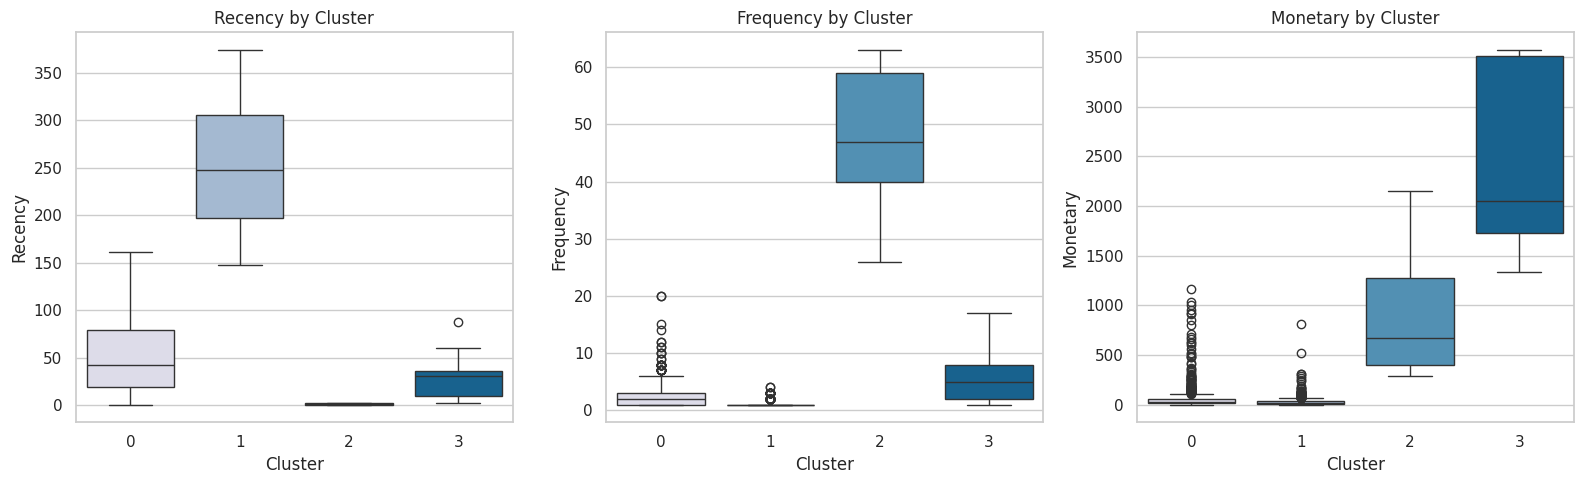

In [43]:
# Visualize the Clusters using Boxplots
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(x='Cluster', y='Recency', data=rfm, ax=axes[0], palette='PuBu')
axes[0].set_title('Recency by Cluster', fontsize=12)

sns.boxplot(x='Cluster', y='Frequency', data=rfm, ax=axes[1], palette='PuBu')
axes[1].set_title('Frequency by Cluster', fontsize=12)

sns.boxplot(x='Cluster', y='Monetary', data=rfm, ax=axes[2], palette='PuBu')
axes[2].set_title('Monetary by Cluster', fontsize=12)

plt.tight_layout()
plt.show()